# Metasurface: microwave frequency selective surface (FSS)
 12GHz bandstop FSS: periodic metal cross array on dielectric substrate. One unit cell with periodic (Bloch) boundaries, excited by a plane wave at normal or oblique incidence `theta`. Compare with [Tidy3D example](https://www.flexcompute.com/tidy3d/examples/notebooks/MicrowaveFrequencySelectiveSurface)

[Run in Lumi Colab](https://hub.luminescentai.com/hub/user-redirect/lab/tree/tutorials/metasurfaces/FSS/FSS.ipynb)

## Setup 

lumi backend: None
using simulation folder runs/FSS


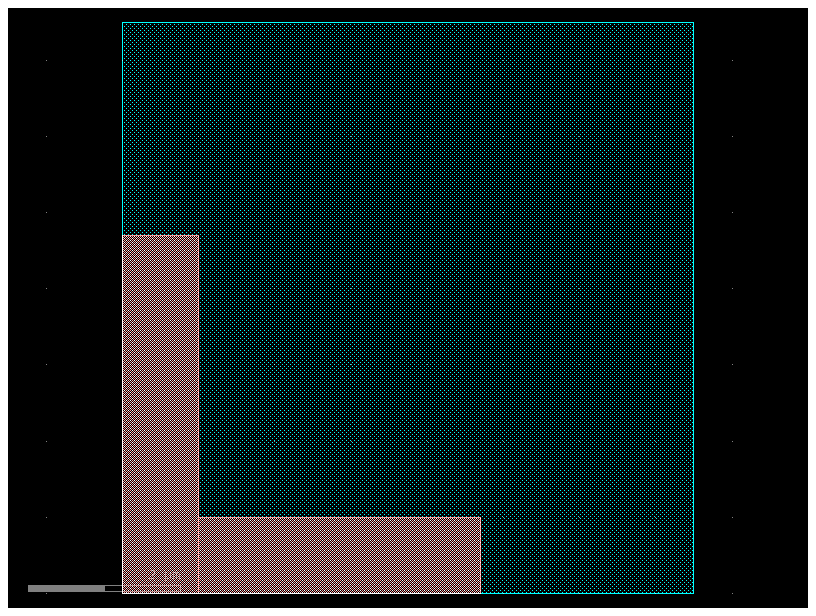

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

# simulation folder
path = os.path.join("runs", "FSS")

# dims [mm]
# length units are arbitrary so long as they're consistent
P = 15  # periodicity
L = 9.4  # length of cross
W = 2.0  # width of cross stub
h_sub = 2.2  # substrate thickness
h_metal = 0.1  # metal thickness

# frequencies [GHz]
# spectrum computed from single FDTD run. more frequencies slightly increases runtime
frequency = 12
bandwidth = 4
nfs = 81
frequencies = np.linspace(frequency - bandwidth / 2, frequency + bandwidth / 2, nfs)

c0 = 300  # speed of light [mm GHz]

# incidence angle [degrees] from z in xz plane. E along y (TE)
theta = 0

def setup(path, frequency, frequencies, P, L, W, h_sub, h_metal, theta):
    # simulation parameters
    nres = 16
    dx = W / 8  # desired resolution near metal
    stop_decay = 1e-3
    PML_decay = 0.001  # x y z
    courant = 0.9
    subpixel_smoothing = 1
    shot_every = 2.5  # movie [periods]
    views = [lumi.view("Ey", z=h_metal / 2)]

    # one unit cell, periodic in x y. Bloch wavevector sets incidence angle (exact at center frequency)
    boundaries = ["periodic", "periodic", "PML"]
    k_bloch = lumi.bloch_wavevector(theta, 0, dim=3, f=frequency, c0=c0)

    # margins
    # air gap keeps evanescent resonant field from coupling to PML
    gap = 30.0
    source_offset = 2.0

    # vertical dims
    z_o1 = h_metal + gap
    z_o2 = -h_sub - gap
    zmin = z_o2
    zmax = z_o1 + source_offset

    # materials
    # refine mesh in substrate and metal: n sets mesh density relative to vacuum
    n = (c0 / frequency / nres) / dx
    materials = {
        "air": lumi.material(1),
        "sub": lumi.material(epsilon=2.5),
        "PEC": lumi.PEC_material(n),
    }
    background = "air"

    # layers
    METAL = 1, 0
    SUB = 2, 0
    layer_stack = LayerStack(
        layers={
            "metal": LayerLevel(
                layer=LogicalLayer(layer=METAL),
                thickness=h_metal,
                zmin=0,
                material="PEC",
                mesh_order=1,
            ),
            "sub": LayerLevel(
                layer=LogicalLayer(layer=SUB),
                thickness=h_sub,
                zmin=-h_sub,
                material="sub",
                mesh_order=2,
            ),
        }
    )

    # make component in gdsfactory. alternatively can import .gds into gdsfactory
    # cross unit cell centered at origin
    c = gf.Component()
    c.add_polygon([(-W / 2, -L / 2), (W / 2, -L / 2), (W / 2, L / 2), (-W / 2, L / 2)], layer=METAL)
    c.add_polygon([(-L / 2, -W / 2), (L / 2, -W / 2), (L / 2, W / 2), (-L / 2, W / 2)], layer=METAL)
    c.add_polygon([(-P / 2, -P / 2), (P / 2, -P / 2), (P / 2, P / 2), (-P / 2, P / 2)], layer=SUB)
    c.plot()

    bbox = c.bbox_np().tolist()
    bbox[0].append(zmin)
    bbox[1].append(zmax)

    # sources, monitors
    # plane wave on face frame spanning the cell. E along y, H along x
    # wave admittance in air: Hx/Ey = cos(theta) in magnitude (sign fixed automatically)
    frames = [lumi.face("plane_wave", modes=[[{"Ey": 1, "Hx": -np.cos(np.deg2rad(theta))}]])]

    # dim: outward normal axis. source injects into cell, monitors record in (-) and out (+) waves
    sources = [
        lumi.source(
            "o1", z_o1 + source_offset, dim=3,
            frame="plane_wave",
            f=frequency,
            bandwidth=max(max(frequencies) - min(frequencies), frequency / 4),
        )
    ]

    monitors = [
        lumi.monitor("o1", z_o1, dim=3, frame="plane_wave"),
        lumi.monitor("o2", z_o2, dim=-3, frame="plane_wave"),
    ]

    # writes .obj mesh files from gdsfactory component
    lumi.mesh(path, c, layer_stack, materials, zmin, zmax)

    # writes setup file
    lumi.setup(
        path=path,
        f=frequency,
        fs=frequencies,
        c0=c0,
        materials=materials,
        background=background,
        boundaries=boundaries,
        k_bloch=k_bloch,
        bbox=bbox,
        #
        frames=frames,
        sources=sources,
        monitors=monitors,
        #
        nres=nres,
        courant=courant,
        PML_decay=PML_decay,
        subpixel_smoothing=subpixel_smoothing,
        # 
        views=views,
        shot_every=shot_every,
        stop_decay=stop_decay,
        device="gpu",
    )


setup(path, frequency, frequencies, P, L, W, h_sub, h_metal, theta)

## Solve

In [2]:
lumi.solve(path)

backend using simulation folder runs/FSS
setting up simulation...
processing geometry bodies...
generating voxels...
subpixel smoothing: 1.629317 seconds (9.74 M allocations: 431.472 MiB, 2.56% gc time, 224.68% compilation time)
making sources o1 ...
making monitors o1 o2 ...
run: runs/FSS
processor: CPU
cpu threads: 16

nres: 16.0
courant: 0.9
subpixel_smoothing: 1
  
boundaries: [:PEC :PEC; :PMC :PMC; :PML :PML]

sources
   o1: 0, 0, 32.1 

monitors
   o1: 0, 0, 30.1 
   o2: 0, 0, -32.2 

original size: (24, 24, 57)
padded size: (24, 24, 91)
cell count: 52,416

step size: 321.0 steps/period
source duration: 3 periods

max time: 100 periods    
max steps: 32,100
max load: 1,682,553,600 cell-steps
energy decay threshold: 0.001

running simulation...
accumulating dft field...
period 2.5, 4.33 seconds/period
period 5.0, decay: 0.325, 0.121 seconds/period
period 7.5, decay: 0.035, 0.091 seconds/period
period 10.01, decay: 0.002, 0.094 seconds/period
period 10.77 stop on energy decay
simul

## Movie

Video generated successfully at runs/FSS/Ex_0_0_0.05.webp!


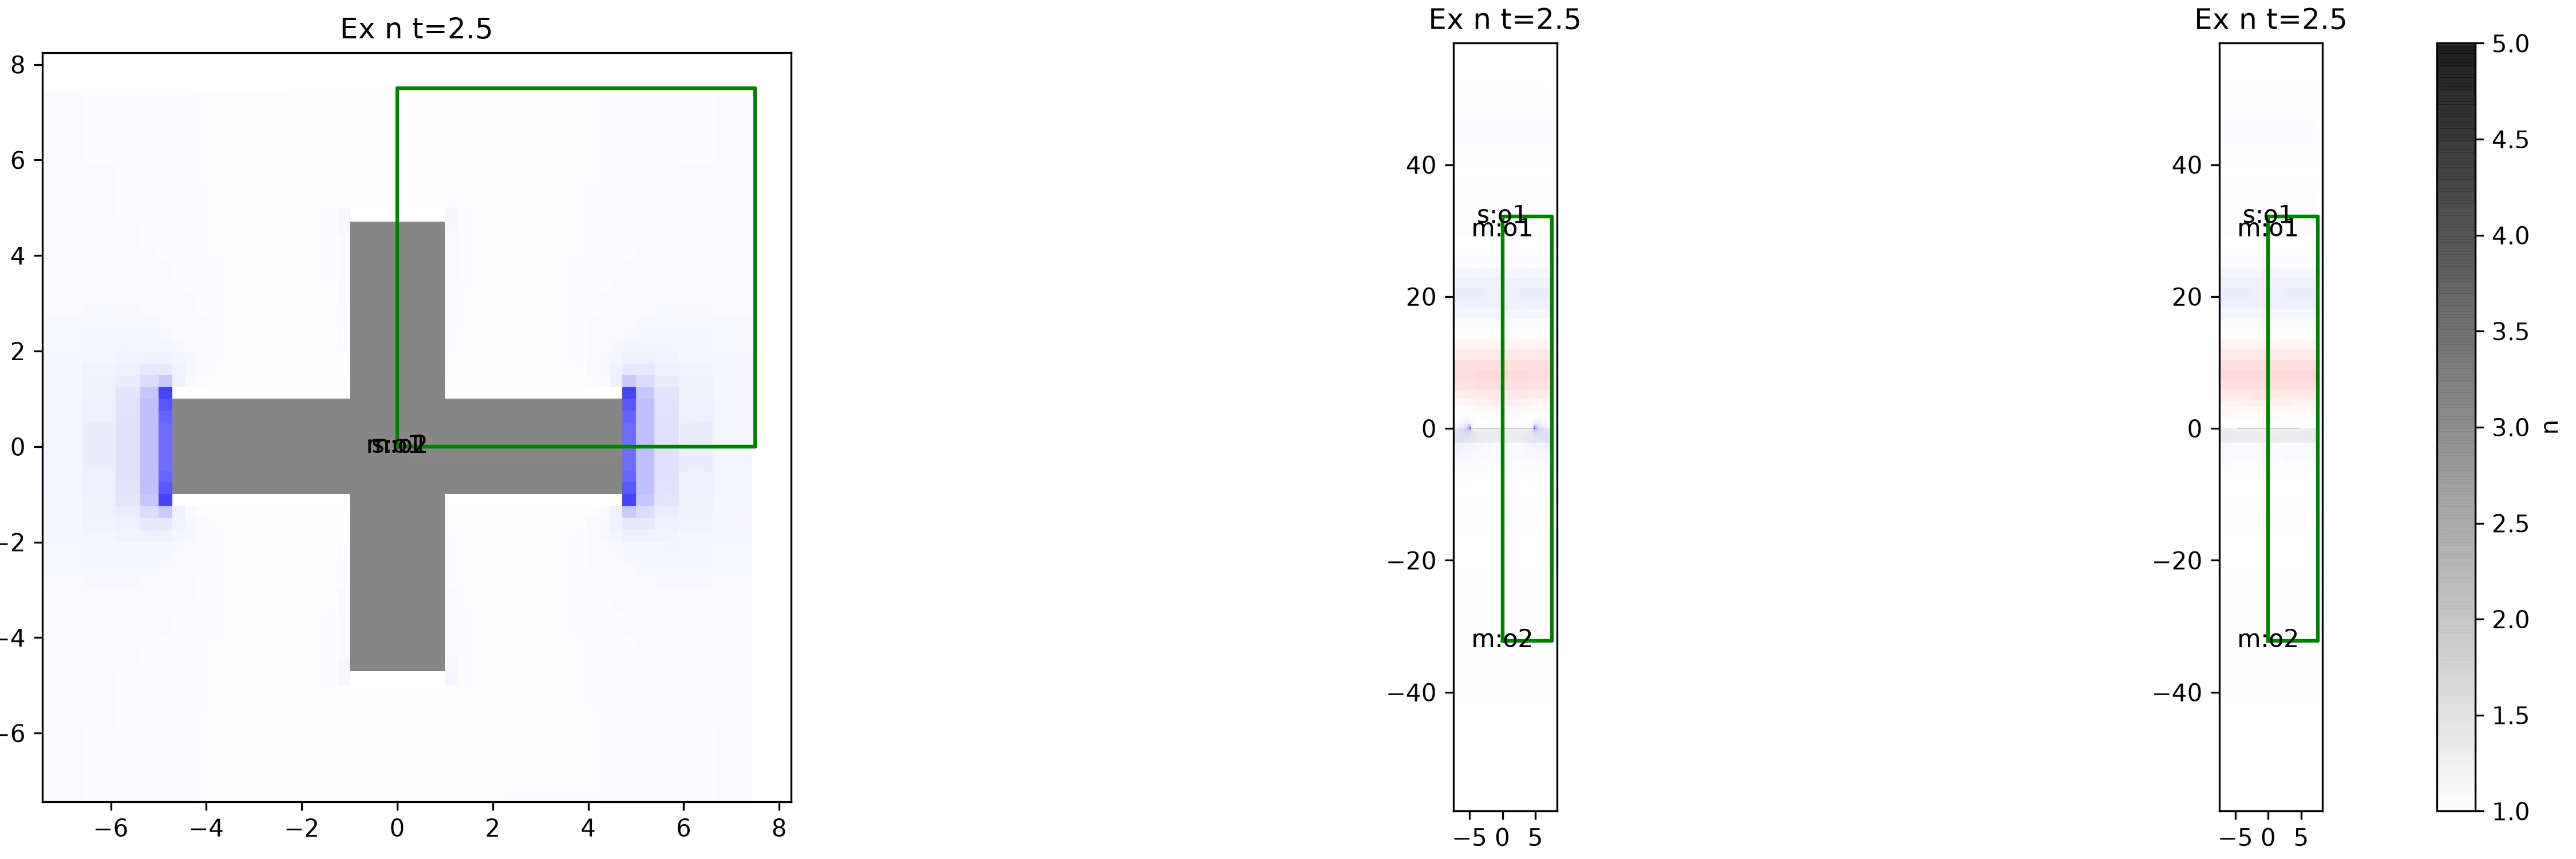

In [3]:
lumi.movie(path)

## Results

loading solution from runs/FSS
may take a minute if simulation folder is remotely mounted


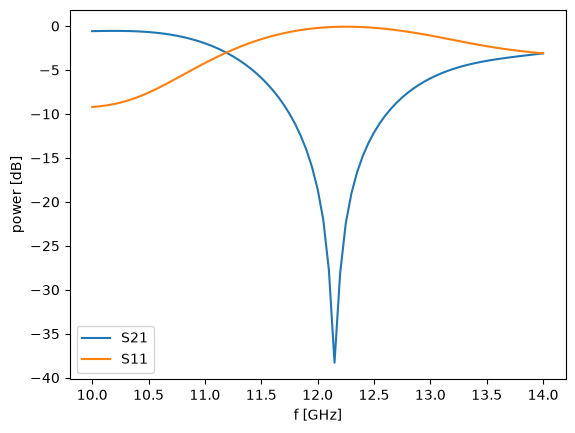

In [4]:
sol = lumi.load(path)
o1 = sol["monitors"]["o1"]
o2 = sol["monitors"]["o2"]

# + denotes outgoing mode (wrt port monitor outward normal), - incoming
S21 = o2["modes"][0]["+"] / o1["modes"][0]["-"]
S11 = o1["modes"][0]["+"] / o1["modes"][0]["-"]

plt.figure()
plt.plot(frequencies, 10 * np.log10(np.abs(S21)**2), label="S21")
plt.plot(frequencies, 10 * np.log10(np.abs(S11)**2), label="S11")
plt.xlabel("f [GHz]")
plt.ylabel("power [dB]")
plt.legend()
plt.show()